# Chapter 15: Choosing Honest Charts

The programs from Chapter 15 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Where the Axis Starts

`truncated_axis.py`

Saved truncated_axis.png


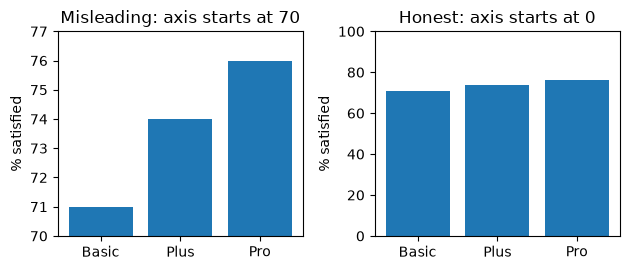

In [1]:
import matplotlib.pyplot as plt

plans = ["Basic", "Plus", "Pro"]
satisfied = [71, 74, 76]  # percent of customers satisfied

fig, (bad, good) = plt.subplots(1, 2, figsize=(6.4, 2.8))
bad.bar(plans, satisfied)
bad.set_ylim(70, 77)
bad.set_title("Misleading: axis starts at 70")
good.bar(plans, satisfied)
good.set_ylim(0, 100)
good.set_title("Honest: axis starts at 0")
for ax in (bad, good):
    ax.set_ylabel("% satisfied")
fig.tight_layout()
fig.savefig("truncated_axis.png")
print("Saved truncated_axis.png")

## Small Multiples

`small_multiples.py`

Saved small_multiples.png


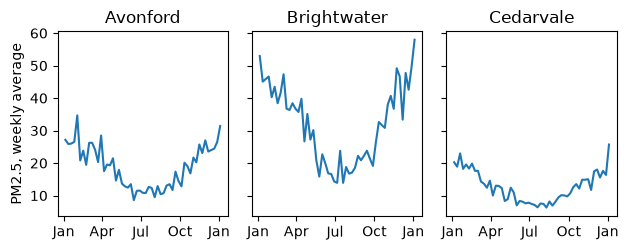

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

air = pd.read_csv("../data/air_quality.csv", parse_dates=["date"])
weekly = air.set_index("date").groupby("city")["pm25"].resample("W").mean()

cities = ["Avonford", "Brightwater", "Cedarvale"]
fig, axes = plt.subplots(1, 3, figsize=(6.4, 2.6), sharey=True)
for ax, city in zip(axes, cities):
    ax.plot(weekly[city].index, weekly[city])
    ax.set_title(city)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_ylabel("PM2.5, weekly average")
fig.tight_layout()
fig.savefig("small_multiples.png")
print("Saved small_multiples.png")